# Date coverage
Share of all individuals in the database with each kind of date, split by precision.

In [1]:
import duckdb
import polars as pl

from style import *

DB_PATH = '../data/cultura/humans_clean_non_enriched_v3.duckdb'

PRECISE = ['day', 'month', 'year', 'decade']
MID_DECADE = 5

pl.Config.set_tbl_rows(40)
pl.Config.set_fmt_str_lengths(80)

connection = duckdb.connect(DB_PATH, read_only=True)

## Load the data
"Year or decade" means a date precise to the day, month, year or decade. "Coarser" is a century or millennium date.

### Birth, death and floruit dates

In [2]:
precise_sql = "', '".join(PRECISE)
individual_dates = connection.execute(f'''
    SELECT entity.qid AS qid,
           len(list_filter(birth_date, date -> date.year IS NOT NULL AND date.precision IN ('{precise_sql}'))) > 0 AS birth_precise,
           len(list_filter(birth_date, date -> date.year IS NOT NULL)) > 0 AS birth_any,
           len(list_filter(death_date, date -> date.year IS NOT NULL AND date.precision IN ('{precise_sql}'))) > 0 AS death_precise,
           len(list_filter(death_date, date -> date.year IS NOT NULL)) > 0 AS death_any,
           len(list_filter(floruit_date, date -> date.year IS NOT NULL AND date.precision IN ('{precise_sql}'))) > 0 AS floruit_precise,
           len(list_filter(floruit_date, date -> date.year IS NOT NULL)) > 0 AS floruit_any,
           list_min([date.year FOR date IN list_concat(birth_date, death_date, floruit_date) IF date.year IS NOT NULL]) AS first_year
    FROM individual
    WHERE len(birth_date) > 0 OR len(death_date) > 0 OR len(floruit_date) > 0
''').pl()
print(f'{individual_dates.height:,} individuals with a birth, death or floruit property')
individual_dates.sample(5, seed=0)

7,794,340 individuals with a birth, death or floruit property


qid,birth_precise,birth_any,death_precise,death_any,floruit_precise,floruit_any,first_year
str,bool,bool,bool,bool,bool,bool,i64
"""Q133640970""",true,true,false,false,false,false,1975
"""Q137114377""",true,true,false,false,false,false,1932
"""Q135580495""",true,true,false,false,false,false,1811
"""Q10281542""",true,true,true,true,false,false,1865
"""Q20606743""",true,true,true,true,false,false,1929


### Work dates
A work's date is its publication date, else its inception, as in notebook 15.

In [3]:
works = connection.execute(f'''
    WITH dated AS (
        SELECT individual_work.qid,
               individual_work.work_qid,
               coalesce(work.publication_date.year, work.inception.year) AS year,
               CASE WHEN work.publication_date.year IS NOT NULL THEN work.publication_date.precision
                    ELSE work.inception.precision END AS precision
        FROM individual_work
        JOIN work ON work.entity.qid = individual_work.work_qid
        WHERE coalesce(work.publication_date.year, work.inception.year) IS NOT NULL
    )
    SELECT qid,
           count(DISTINCT work_qid) AS dated_works,
           count(DISTINCT work_qid) FILTER (WHERE precision IN ('{precise_sql}')) AS precise_works,
           min(year) AS first_work_year
    FROM dated
    GROUP BY qid
''').pl()
print(f'{works.height:,} individuals with at least one dated work')
works.sample(5, seed=0)

2,780,765 individuals with at least one dated work


qid,dated_works,precise_works,first_work_year
str,i64,i64,i64
"""Q94464801""",10,10,2013
"""Q57952413""",6,6,2016
"""Q114444294""",34,34,1995
"""Q114302134""",3,3,2013
"""Q96064307""",11,11,2010


### "fl." in descriptions
Same parsing as notebook 15: the first year after "fl." is year-precise, "1930s" is decade-precise. A description giving only a century ("fl. 5th century", "fl. 15. century") is coarser; its year is the start of that century.

In [4]:
fl_pattern = r'\bfl\.\s*(?:c\.|ca\.|circa|about|in the|around)?\s*(\d{1,4})(s?)\b(?:[^,;)]*?\b(BCE?)\b)?'
century_pattern = r'\bfl\.[^,;)]*?\b(\d{1,2})(?:st|nd|rd|th|\.)?\s*(?:-\s*\d{1,2}(?:st|nd|rd|th|\.)?\s*)?(century|centuries|millennium)(?:[^,;)]*?\b(BCE?)\b)?'

fl_text = (
    connection.execute('''
        SELECT entity.qid AS qid, entity.description AS description
        FROM individual
        WHERE regexp_matches(entity.description, '\\bfl\\.')
    ''').pl()
    .with_columns(
        pl.col('description').str.extract_groups(fl_pattern).alias('match'),
        pl.col('description').str.extract_groups(century_pattern).alias('century_match'),
        pl.col('description').str.contains(r'\bfl\.\s*\d{1,2}\.').alias('is_ordinal_century'),
    )
    .with_columns(
        pl.col('match').struct.field('1').cast(pl.Int64).alias('year'),
        pl.col('match').struct.field('2').eq('s').alias('is_decade'),
        pl.col('match').struct.field('3').is_not_null().alias('is_bc'),
        pl.col('century_match').struct.field('1').cast(pl.Int64).alias('ordinal'),
        pl.col('century_match').struct.field('2').eq('millennium').alias('is_millennium'),
        pl.col('century_match').struct.field('3').is_not_null().alias('is_century_bc'),
    )
    .with_columns(
        pl.when(pl.col('is_ordinal_century')).then(None)
        .when(pl.col('is_decade')).then(pl.col('year') + MID_DECADE)
        .otherwise(pl.col('year')).alias('year'))
    .with_columns(pl.when(pl.col('is_bc')).then(-pl.col('year')).otherwise(pl.col('year')).alias('fl_precise_year'))
    .with_columns(
        pl.when(pl.col('is_millennium')).then((pl.col('ordinal') - 1) * 1000)
        .otherwise((pl.col('ordinal') - 1) * 100).alias('coarse_year'))
    .with_columns(
        pl.when(pl.col('is_century_bc')).then(-pl.col('coarse_year') - 100 * (~pl.col('is_millennium')).cast(pl.Int64) - 1000 * pl.col('is_millennium').cast(pl.Int64))
        .otherwise(pl.col('coarse_year')).alias('fl_coarse_year'))
    .select(
        'qid', 'description',
        pl.col('fl_precise_year').is_not_null().alias('fl_precise'),
        (pl.col('fl_precise_year').is_not_null() | pl.col('fl_coarse_year').is_not_null()).alias('fl_any'),
        pl.coalesce('fl_precise_year', 'fl_coarse_year').alias('fl_year'),
    )
)
assert fl_text['qid'].is_unique().all()
print(f'{fl_text.height:,} individuals with "fl." in their description')
print(f"{fl_text['fl_precise'].sum():,} with a year or decade, {(fl_text['fl_any'] & ~fl_text['fl_precise']).sum():,} with only a century or millennium")
print(f"{(~fl_text['fl_any']).sum():,} with no readable date after \"fl.\"")
fl_text.sample(10, seed=1)

7,845 individuals with "fl." in their description
7,257 with a year or decade, 268 with only a century or millennium
320 with no readable date after "fl."


qid,description,fl_precise,fl_any,fl_year
str,str,bool,bool,i64
"""Q59531265""","""born:1600|died:1619|; Bauer, Konrad, -1619; Bauer, Konrad, 15..-1619?; Agricola,…",true,true,1600
"""Q41618149""","""(fl. 1553)""",true,true,1553
"""Q111509644""","""Italian publisher and bookseller (fl. 1656-1673)""",true,true,1656
"""Q41618010""","""(fl. 1822)""",true,true,1822
"""Q118173726""","""Italian jurist (fl. 1905)""",true,true,1905
"""Q21395305""","""lichenologist (fl. 1980)""",true,true,1980
"""Q97321388""","""Italian printer (fl. 1817-1822)""",true,true,1817
"""Q18759349""","""Lewis, Joseph (fl. 1750–1774), poet and ivory-turner""",true,true,1750
"""Q111342419""","""of Salisbury, N.C. (fl. 1876-1878)""",true,true,1876


## One row per dated individual
An individual counts as dated when at least one of these sources gives a year, at any precision.

In [5]:
flags = (
    individual_dates
    .join(works, on='qid', how='full', coalesce=True)
    .join(fl_text.drop('description'), on='qid', how='full', coalesce=True)
    .with_columns(
        pl.col('dated_works', 'precise_works').fill_null(0),
        pl.col('^.*_(precise|any)$').fill_null(False),
    )
    .with_columns(pl.min_horizontal('first_year', 'first_work_year', 'fl_year').alias('anchor_year'))
)
assert flags['qid'].is_unique().all()

dated = flags.filter(pl.col('anchor_year').is_not_null())
database_size = connection.execute('SELECT count(*) FROM individual').fetchone()[0]
print(f'{database_size:,} individuals in the database')
print(f'{dated.height:,} dated individuals ({100 * dated.height / database_size:.1f}%)')

13,002,897 individuals in the database
9,968,298 dated individuals (76.7%)


## Coverage
"Coarser only" counts individuals whose best date of that kind is a century or millennium. For two work dates: at least two dated works, but fewer than two dated to the year or decade.

In [6]:
date_kinds = {
    'Birth date': (pl.col('birth_precise'), pl.col('birth_any')),
    'Death date': (pl.col('death_precise'), pl.col('death_any')),
    'Floruit date': (pl.col('floruit_precise'), pl.col('floruit_any')),
    'At least 1 work date': (pl.col('precise_works') >= 1, pl.col('dated_works') >= 1),
    'At least 2 work dates': (pl.col('precise_works') >= 2, pl.col('dated_works') >= 2),
    '"fl." in description': (pl.col('fl_precise'), pl.col('fl_any')),
}

coverage = pl.concat([
    dated.select(pl.lit(kind).alias('date'), precise.sum().alias('precise'), any_precision.sum().alias('any'))
    for kind, (precise, any_precision) in date_kinds.items()
]).with_columns(
    (100 * pl.col('precise') / database_size).alias('year_or_decade_%'),
    (100 * (pl.col('any') - pl.col('precise')) / database_size).alias('coarser_only_%'),
    (100 * pl.col('any') / database_size).alias('any_precision_%'),
)
assert (coverage['precise'] <= coverage['any']).all()
coverage

date,precise,any,year_or_decade_%,coarser_only_%,any_precision_%
str,u32,u32,f64,f64,f64
"""Birth date""",7349789,7487896,56.524242,1.062125,57.586367
"""Death date""",3501000,3531434,26.924769,0.234056,27.158825
"""Floruit date""",55835,68641,0.429404,0.098486,0.52789
"""At least 1 work date""",2773277,2780765,21.328147,0.057587,21.385734
"""At least 2 work dates""",1789214,1794294,13.760118,0.039068,13.799186
"""""fl."" in description""",7257,7525,0.055811,0.002061,0.057872


### Table: date coverage of the whole database (% of all individuals)

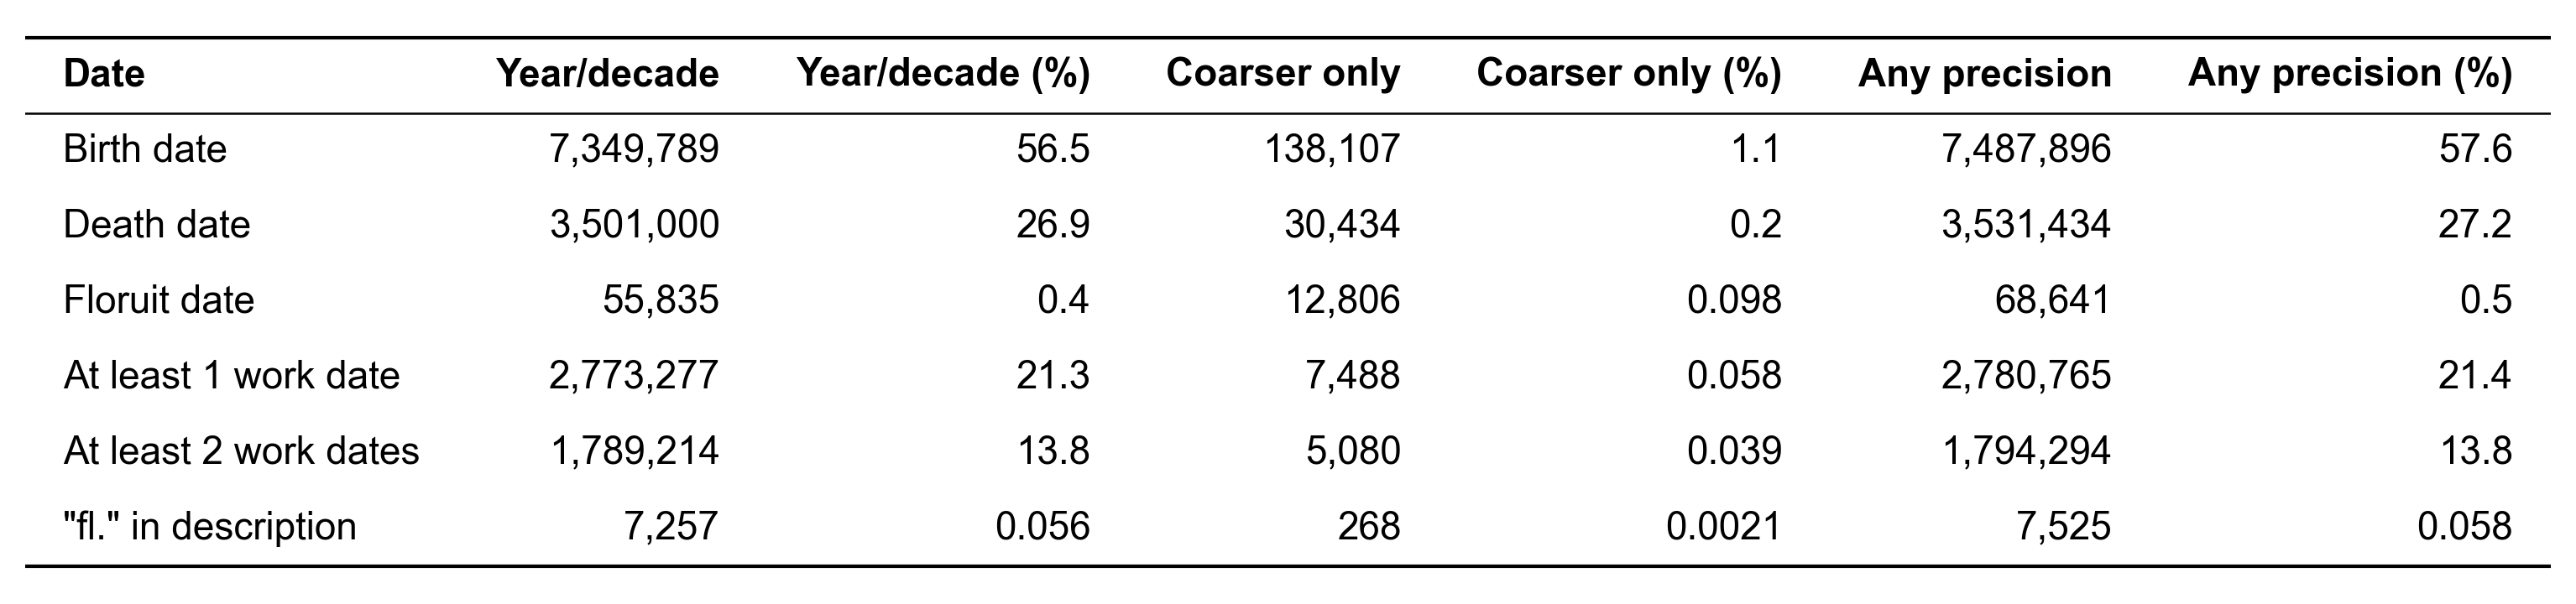

In [7]:
def percent(value):
    if value == 0:
        return '0'
    if value >= 0.1:
        return f'{value:.1f}'
    return f'{value:.2g}'


show_table(coverage.select(
    pl.col('date').alias('Date'),
    pl.col('precise').alias('Year/decade'),
    pl.col('year_or_decade_%').map_elements(percent, return_dtype=pl.String).alias('Year/decade (%)'),
    (pl.col('any') - pl.col('precise')).alias('Coarser only'),
    pl.col('coarser_only_%').map_elements(percent, return_dtype=pl.String).alias('Coarser only (%)'),
    pl.col('any').alias('Any precision'),
    pl.col('any_precision_%').map_elements(percent, return_dtype=pl.String).alias('Any precision (%)'),
))